In [1]:
import os, json, time, contextlib, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
from PIL import Image

DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
BATCH, VAL = 256, 5000   # VAL: held-out train images used to score every run
SHORT, LONG = 15, 150    # epochs for sweep runs / final runs
RESULTS = 'results.csv'  # every finished run is appended here; reruns skip names already in it
print(DEVICE)

mps


In [2]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
test_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

def train_tf(aug):  # 'basic' = crop+flip, 'ta' adds TrivialAugment, 'erase' adds RandomErasing
    t = [T.RandomCrop(32, padding=4, padding_mode='reflect'), T.RandomHorizontalFlip()]
    if 'ta' in aug: t.append(T.TrivialAugmentWide())
    t += [T.ToTensor(), T.Normalize(MEAN, STD)]
    if 'erase' in aug: t.append(T.RandomErasing(p=0.25))
    return T.Compose(t)

def load_imgs(files, folder):  # PNGs -> (N, 32, 32, 3) uint8, loaded once into RAM
    return np.stack([np.array(Image.open(f'data/{folder}/{f}').convert('RGB')) for f in files])

class ImgDS(torch.utils.data.Dataset):
    def __init__(s, x, y, tf): s.x, s.y, s.tf = x, y, tf
    def __len__(s): return len(s.x)
    def __getitem__(s, i): return s.tf(Image.fromarray(s.x[i])), s.y[i]

train_df = pd.read_csv('data/train_labels.csv')  # id, filename, label
X, Y = load_imgs(train_df.filename, 'train_images'), train_df.label.to_numpy()
perm = np.random.default_rng(0).permutation(len(X)); vi, ti = perm[:VAL], perm[VAL:]
val_ds = ImgDS(X[vi], Y[vi], test_tf)
val_dl = torch.utils.data.DataLoader(val_ds, 512)
print(len(ti), len(vi))
# ponytail: single-process loading (~7s/epoch); forked workers hit 'Broken pipe' in Jupyter on macOS
kw = dict(num_workers=0)

45000 5000


In [3]:
class Block(nn.Module):  # out = ReLU(F(x) + S(x)), S = identity or 1x1 projection
    def __init__(s, cin, cout, stride, k):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                            nn.Conv2d(cout, cout, k, 1, k // 2, bias=False), nn.BatchNorm2d(cout))
        s.skip = nn.Identity() if stride == 1 and cin == cout else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(s, x): return F.relu(s.f(x) + s.skip(x))

class ResNet(nn.Module):  # one stage per width; every stage after the first halves resolution
    def __init__(s, widths, blocks, k=3, drop=0.0, n_cls=10):
        super().__init__()
        layers, cin = [nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True)], widths[0]
        for i, (w, n) in enumerate(zip(widths, blocks)):
            for j in range(n):
                layers.append(Block(cin, w, 2 if i > 0 and j == 0 else 1, k)); cin = w
        s.body = nn.Sequential(*layers)
        s.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(cin, n_cls))
    def forward(s, x): return s.head(s.body(x))

def build(cfg):
    m = ResNet(cfg['widths'], cfg['blocks'], cfg['k'], cfg['drop']).to(DEVICE, memory_format=torch.channels_last)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    assert n <= 5_000_000, f'{n:,} trainable params > 5M'
    return m, n

In [4]:
crit = nn.CrossEntropyLoss(label_smoothing=0.1)
amp = lambda: torch.autocast('cuda', dtype=torch.float16) if DEVICE == 'cuda' else contextlib.nullcontext()

def make_opt(params, opt, lr, wd):
    if opt == 'sgd': return torch.optim.SGD(params, lr, momentum=0.9, nesterov=True, weight_decay=wd)
    if opt == 'adamw': return torch.optim.AdamW(params, lr, weight_decay=wd)
    if opt == 'rmsprop': return torch.optim.RMSprop(params, lr, momentum=0.9, weight_decay=wd)
    raise ValueError(opt)

@torch.no_grad()
def predict(model, dl):  # logits with hflip TTA
    model.eval(); out = []
    for x, *_ in dl:
        x = x.to(DEVICE, memory_format=torch.channels_last)
        with amp(): out.append((model(x) + model(x.flip(3))).float().cpu())
    return torch.cat(out)

def run(name, epochs=SHORT, save=False, idx=None, **cfg):  # idx: training indices (default: the 45k split)
    if os.path.exists(RESULTS) and name in pd.read_csv(RESULTS)['name'].values: return print('done already:', name)
    torch.manual_seed(0); t0 = time.time()
    model, n = build(cfg)
    dl = torch.utils.data.DataLoader(ImgDS(X[ti if idx is None else idx], Y[ti if idx is None else idx], train_tf(cfg['aug'])), BATCH, shuffle=True, drop_last=True, **kw)
    opt = make_opt(model.parameters(), cfg['opt'], cfg['lr'], cfg['wd'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg['lr'], epochs=epochs, steps_per_epoch=len(dl))
    scaler = torch.amp.GradScaler(enabled=DEVICE == 'cuda')
    hist = []
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y in dl:
            x, y = x.to(DEVICE, memory_format=torch.channels_last, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with amp(): loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        acc = (predict(model, val_dl).argmax(1) == torch.from_numpy(val_ds.y)).float().mean().item()
        hist.append([round(tot / len(dl), 4), round(acc, 4)])
        print(f'\r{name}  ep {ep+1}/{epochs}  loss {hist[-1][0]:.3f}  val {acc:.4f}', end='')
    mins = (time.time() - t0) / 60; print(f'  ({mins:.1f} min)')
    row = dict(name=name, val_acc=acc, params=n, epochs=epochs, minutes=round(mins, 1), cfg=json.dumps(cfg), hist=json.dumps(hist))
    pd.DataFrame([row]).to_csv(RESULTS, mode='a', header=not os.path.exists(RESULTS), index=False)
    if save: torch.save(model.state_dict(), name.replace('/', '_') + '.pt')

def best(*prefixes):  # show runs in these stages, return the config of the best one
    r = pd.read_csv(RESULTS); r = r[r['name'].str.startswith(prefixes)].sort_values('val_acc', ascending=False)
    display(r[['name', 'val_acc', 'params', 'minutes']])
    return json.loads(r.iloc[0].cfg)

In [5]:
# Stage 1: architecture (fixed SGD lr 0.1, wd 5e-4, TrivialAugment + erasing)
BASE = dict(widths=[64, 128, 256], blocks=[3, 4, 3], k=3, drop=0.0, opt='sgd', lr=0.1, wd=5e-4, aug='ta+erase')
ARCHS = {
    'base':         dict(widths=[64, 128, 256], blocks=[3, 4, 3]),         # 4.62M
    'deep_narrow':  dict(widths=[48, 96, 192], blocks=[6, 6, 5]),          # more depth, thinner
    'wide_shallow': dict(widths=[96, 192, 320], blocks=[2, 2, 2]),         # less depth, wider
    'early_heavy':  dict(widths=[96, 160, 256], blocks=[4, 4, 2]),         # more compute at 32x32 / 16x16
    '4stage':       dict(widths=[48, 96, 192, 288], blocks=[1, 2, 2, 2]),  # extra downsample to 4x4
    'k5':           dict(widths=[40, 80, 160], blocks=[2, 3, 3], k=5),     # 5x5 kernels, narrower
}
for n, a in ARCHS.items(): run(f'arch/{n}', **{**BASE, **a})
cfg = best('arch/')

arch/base  ep 15/15  loss 0.940  val 0.9140  (14.0 min)
arch/deep_narrow  ep 15/15  loss 0.957  val 0.9070  (17.0 min)
arch/wide_shallow  ep 15/15  loss 0.957  val 0.9182  (16.3 min)
arch/early_heavy  ep 15/15  loss 0.940  val 0.9210  (24.1 min)
arch/4stage  ep 15/15  loss 0.980  val 0.9010  (7.4 min)
arch/k5  ep 15/15  loss 0.977  val 0.9044  (18.8 min)


,name,val_acc,params,minutes
3,arch/early_heavy,0.9210,4621354,24.1
2,arch/wide_shallow,0.9182,4902506,16.3
0,arch/base,0.9140,4623178,14.0
1,arch/deep_narrow,0.9070,4388794,17.0
5,arch/k5,0.9044,4582450,18.8
4,arch/4stage,0.9010,4318714,7.4


In [6]:
# Stage 2: optimizer + lr on the best architecture (its SGD lr 0.1 run is the baseline)
OPTS = {
    'sgd_lr0.05':    dict(opt='sgd', lr=0.05),
    'sgd_lr0.2':     dict(opt='sgd', lr=0.2),
    'adamw_lr1e-3':  dict(opt='adamw', lr=1e-3, wd=5e-2),  # AdamW uses decoupled wd, so a larger value
    'adamw_lr3e-3':  dict(opt='adamw', lr=3e-3, wd=5e-2),
    'rmsprop_lr3e-4': dict(opt='rmsprop', lr=3e-4),
    'rmsprop_lr1e-3': dict(opt='rmsprop', lr=1e-3),
}
for n, o in OPTS.items(): run(f'opt/{n}', **{**cfg, **o})
cfg = best('arch/', 'opt/')

opt/sgd_lr0.05  ep 15/15  loss 0.961  val 0.9168  (24.1 min)
opt/sgd_lr0.2  ep 15/15  loss 0.930  val 0.9240  (28.1 min)
opt/adamw_lr1e-3  ep 15/15  loss 0.959  val 0.9138  (25.9 min)
opt/adamw_lr3e-3  ep 15/15  loss 0.941  val 0.9192  (26.6 min)
opt/rmsprop_lr3e-4  ep 15/15  loss 1.049  val 0.8878  (21.7 min)
opt/rmsprop_lr1e-3  ep 15/15  loss 1.285  val 0.8020  (21.0 min)


,name,val_acc,params,minutes
7,opt/sgd_lr0.2,0.9240,4621354,28.1
3,arch/early_heavy,0.9210,4621354,24.1
9,opt/adamw_lr3e-3,0.9192,4621354,26.6
2,arch/wide_shallow,0.9182,4902506,16.3
6,opt/sgd_lr0.05,0.9168,4621354,24.1
0,arch/base,0.9140,4623178,14.0
8,opt/adamw_lr1e-3,0.9138,4621354,25.9
1,arch/deep_narrow,0.9070,4388794,17.0
5,arch/k5,0.9044,4582450,18.8
4,arch/4stage,0.9010,4318714,7.4


In [7]:
# Stage 3: regularization on the best arch + optimizer
REGS = {
    'wd_x0.3':   dict(wd=cfg['wd'] * 0.3),
    'wd_x3':     dict(wd=cfg['wd'] * 3),
    'drop0.2':   dict(drop=0.2),
    'aug_basic': dict(aug='basic'),
    'aug_ta':    dict(aug='ta'),
}
for n, g in REGS.items(): run(f'reg/{n}', **{**cfg, **g})
cfg = best('arch/', 'opt/', 'reg/')

reg/wd_x0.3  ep 15/15  loss 0.936  val 0.9182  (21.3 min)
reg/wd_x3  ep 15/15  loss 0.949  val 0.9228  (21.1 min)
reg/drop0.2  ep 15/15  loss 0.944  val 0.9208  (21.3 min)
reg/aug_basic  ep 15/15  loss 0.581  val 0.9382  (20.9 min)
reg/aug_ta  ep 15/15  loss 0.880  val 0.9264  (21.3 min)


,name,val_acc,params,minutes
15,reg/aug_basic,0.9382,4621354,20.9
16,reg/aug_ta,0.9264,4621354,21.3
7,opt/sgd_lr0.2,0.9240,4621354,28.1
13,reg/wd_x3,0.9228,4621354,21.1
3,arch/early_heavy,0.9210,4621354,24.1
14,reg/drop0.2,0.9208,4621354,21.3
9,opt/adamw_lr3e-3,0.9192,4621354,26.6
12,reg/wd_x0.3,0.9182,4621354,21.3
2,arch/wide_shallow,0.9182,4902506,16.3
6,opt/sgd_lr0.05,0.9168,4621354,24.1


In [8]:
# Long runs: the 2 best distinct sweep configs at LONG epochs
r = pd.read_csv(RESULTS)
top = r[r.epochs == SHORT].sort_values('val_acc', ascending=False).drop_duplicates('cfg').head(2)
for i, (n, c) in enumerate(zip(top['name'], top['cfg']), 1):
    print(f'long/{i} <- {n}'); run(f'long/{i}', epochs=LONG, save=True, **json.loads(c))
best('long/')

long/1 <- reg/aug_basic
long/1  ep 150/150  loss 0.502  val 0.9578  (206.4 min)
long/2 <- reg/aug_ta
long/2  ep 150/150  loss 0.657  val 0.9696  (210.3 min)


,name,val_acc,params,minutes
18,long/2,0.9696,4621354,210.3
17,long/1,0.9578,4621354,206.4


{'widths': [96, 160, 256],
 'blocks': [4, 4, 2],
 'k': 3,
 'drop': 0.0,
 'opt': 'sgd',
 'lr': 0.2,
 'wd': 0.0005,
 'aug': 'ta'}

In [9]:
# Run A: long/2's config with the full augmentation (TrivialAugment + random erasing)
r = pd.read_csv(RESULTS)
cfgA = {**json.loads(r[r['name'] == 'long/2']['cfg'].iloc[0]), 'aug': 'ta+erase'}
run('long/3_ta_erase', epochs=LONG, save=True, **cfgA)
best('long/')

long/3_ta_erase  ep 150/150  loss 0.700  val 0.9706  (216.2 min)


,name,val_acc,params,minutes
19,long/3_ta_erase,0.9706,4621354,216.2
18,long/2,0.9696,4621354,210.3
17,long/1,0.9578,4621354,206.4


{'widths': [96, 160, 256],
 'blocks': [4, 4, 2],
 'k': 3,
 'drop': 0.0,
 'opt': 'sgd',
 'lr': 0.2,
 'wd': 0.0005,
 'aug': 'ta+erase'}

In [10]:
# Final run: best long config retrained on all 50k images (no holdout)
# val_acc for this run is on images it trained on, so it is NOT a validation score
r = pd.read_csv(RESULTS); bl = r[r['name'].str.startswith('long/')].sort_values('val_acc').iloc[-1]
cfgF = json.loads(bl['cfg']); FINAL = 250 if 'erase' in cfgF['aug'] else 200  # heavier aug benefits from longer training
print(f'final <- {bl["name"]} ({bl.val_acc:.4f}), {FINAL} epochs')
run('final/1', epochs=FINAL, save=True, idx=np.arange(len(X)), **cfgF)

final <- long/3_ta_erase (0.9706), 250 epochs
final/1  ep 250/250  loss 0.672  val 0.9996  (384.8 min)


,name,val_acc,params,epochs,minutes,cfg
20,final/1,0.9996,4621354,250,384.8,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
19,long/3_ta_erase,0.9706,4621354,150,216.2,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
18,long/2,0.9696,4621354,150,210.3,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
17,long/1,0.9578,4621354,150,206.4,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
15,reg/aug_basic,0.9382,4621354,15,20.9,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
16,reg/aug_ta,0.9264,4621354,15,21.3,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
7,opt/sgd_lr0.2,0.9240,4621354,15,28.1,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
13,reg/wd_x3,0.9228,4621354,15,21.1,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
3,arch/early_heavy,0.9210,4621354,15,24.1,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."
14,reg/drop0.2,0.9208,4621354,15,21.3,"{""widths"": [96, 160, 256], ""blocks"": [4, 4, 2]..."


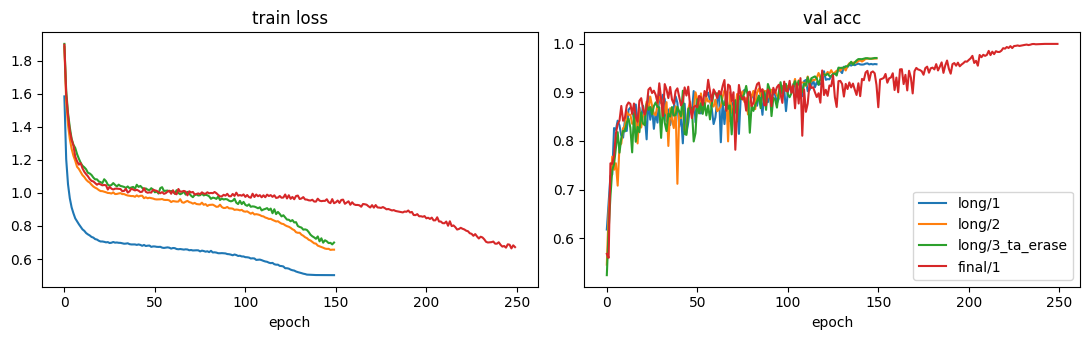

In [11]:
import matplotlib.pyplot as plt
r = pd.read_csv(RESULTS)
display(r.sort_values('val_acc', ascending=False)[['name', 'val_acc', 'params', 'epochs', 'minutes', 'cfg']])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for n, h in zip(r['name'], r['hist']):
    if n.startswith(('long/', 'final/')):
        h = np.array(json.loads(h)); ax[0].plot(h[:, 0], label=n); ax[1].plot(h[:, 1], label=n)
ax[0].set(title='train loss', xlabel='epoch'); ax[1].set(title='val acc', xlabel='epoch'); ax[1].legend(); plt.tight_layout()

In [12]:
# Submission from the final all-data model if it exists, else the best long run
r = pd.read_csv(RESULTS); f = r[r['name'].str.startswith('final/')]
b = f.iloc[-1] if len(f) else r[r['name'].str.startswith('long/')].sort_values('val_acc').iloc[-1]
model, _ = build(json.loads(b.cfg)); model.load_state_dict(torch.load(b['name'].replace('/', '_') + '.pt', map_location=DEVICE))
test_df = pd.read_csv('data/test.csv')  # id, filename
X_test = torch.stack([test_tf(im) for im in load_imgs(test_df.filename, 'test_images')])
preds = predict(model, torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_test), 512)).argmax(1).numpy()
pd.DataFrame({'id': test_df.id, 'label': preds}).to_csv('submission.csv', index=False)
print(b['name'], b.val_acc, np.bincount(preds, minlength=10))

final/1 0.9995999932289124 [174 226 197 214 195 212 183 204 206 189]
